# Prompted LLMs vs fine-tuned models

This notebook compares every system of the project on the SemEval-2023 test set (1,000 posts):

| Kind | Systems | From |
|---|---|---|
| baseline | first sentence of the article | Milestone 2, `simple-baseline.py` |
| fine-tuned | RoBERTa-base QA (strong baseline), DeBERTa-v3-large QA, Flan-T5-large, Llama 3.1 8B (QLoRA) | Milestones 2 and 3 |
| prompted | Llama 3.1 8B, GPT-OSS 20B (local), Claude Sonnet 5.5 and Haiku 5.5, GPT-6.1 Sol and GPT-6 Luna (cloud) | `1-prompted-llms.ipynb` |

It only reads prediction and score files, so it runs in about a minute, without a GPU or API keys. The first cell copies the fine-tuned systems' test predictions and scores from `milestone2/output` and `milestone3/output` into `output/finetuned/`, so the final package holds every system's output.

**What it answers:**
1. **Main table:** all systems, all metrics.
2. **Chart:** BLEU per spoiler type.
3. **Is the difference real?** A paired bootstrap of every prompted LLM against the strong baseline and against our best fine-tuned model.
4. **Same model, prompted vs fine-tuned:** Llama 3.1 8B both ways. What does fine-tuning change?
5. **Probes on 300 test posts:** few-shot vs zero-shot vs closed-book (no article). Do the models know this dataset?
6. **Snapping:** how much copying the answer back onto the article's text helps.
7. **Cost and time:** what each system costs to train and to run.

Run it from `milestone4/code` with `jupyter nbconvert --to notebook --execute --inplace 2-compare.ipynb`. Tables go to `output/compare-*.csv` and `.md`, charts to `output/figures/`.

## Setup

Imports, the list of systems and their files (`spoilerqa/compare.py`), the test set, every system's predictions, scores and per-post BLEU.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from spoilerqa import compare as C
from spoilerqa import llm
from spoilerqa.data import DEFAULT_DATA_DIR, TYPES, build_context, load_jsonl, load_split, post_text, spoiler_type
from spoilerqa.metrics import as_text, ensure_nltk_data
from spoilerqa.tables import to_markdown

ensure_nltk_data()
pd.set_option("display.max_colwidth", 90)

DATA_DIR = Path(os.environ.get("DATA_DIR", DEFAULT_DATA_DIR))
OUTPUT_DIR = Path("../output")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROJECT_ROOT = Path.cwd().resolve().parents[1]

print("fine-tuned files copied into output/finetuned/:", C.collect_finetuned(PROJECT_ROOT, OUTPUT_DIR))
SYSTEMS = C.systems(OUTPUT_DIR)
BY_KEY = {s["key"]: s for s in SYSTEMS}
test = load_split(DATA_DIR, "test")
gold = {r["uuid"]: r for r in test}
preds = {s["key"]: C.load_preds(s["pred"]) for s in SYSTEMS}
scores = {s["key"]: C.load_scores(s["scores"]) for s in SYSTEMS}
bleu = {s["key"]: C.per_post_bleu(test, preds[s["key"]]) for s in SYSTEMS}


def save_table(df, name, digits=4):
    # Every table is written as CSV (for further analysis) and as markdown (for the report notes).
    df.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
    (OUTPUT_DIR / f"{name}.md").write_text(to_markdown(df, digits=digits))


# Chart colors: color = kind of system; text stays in neutral ink.
FAMILY_COLORS = {"baseline": "#8a8984", "fine-tuned": "#2a78d6", "prompted": "#eb6834"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # categorical slots, always in this order
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"


def style_axis(ax, grid_axis="x"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, zorder=0)
    ax.tick_params(colors=INK_2, labelsize=8.5)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(INK_2)


display(pd.DataFrame([{"system": s["label"], "kind": s["family"], "size": s["size"],
                       "worked examples": s.get("k", ""), "predictions": str(s["pred"].relative_to(OUTPUT_DIR))}
                      for s in SYSTEMS]))

/opt/anaconda3/envs/NLP/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fine-tuned files copied into output/finetuned/: 0


,system,kind,size,worked examples,predictions
0,Simple baseline (first sentence),baseline,-,,finetuned/predictions/simple-baseline-test.jsonl
1,RoBERTa-base QA (M2 strong baseline),fine-tuned,125M,,finetuned/predictions/strong-baseline-test.jsonl
2,DeBERTa-v3-large QA,fine-tuned,435M,,finetuned/predictions/deberta-qa-test.jsonl
3,Flan-T5-large,fine-tuned,783M,,finetuned/predictions/flan-t5-test.jsonl
4,"Llama 3.1 8B, fine-tuned (QLoRA)",fine-tuned,8B (42M trained),,finetuned/predictions/llama-qlora-test.jsonl
5,"Llama 3.1 8B, prompted",prompted,8B (4-bit),0,predictions/llama3.1-8b_article_k0_test.jsonl
6,GPT-OSS 20B,prompted,21B MoE (4-bit),0,predictions/gpt-oss-20b_article_k0_test.jsonl
7,Claude Sonnet 5.5,prompted,not disclosed,6,predictions/claude-sonnet-5.5_article_k6_test.jsonl
8,Claude Haiku 5.5,prompted,not disclosed,3,predictions/claude-haiku-5.5_article_k3_test.jsonl
9,GPT-6.1 Sol,prompted,not disclosed,6,predictions/gpt-6.1-sol_article_k6_test.jsonl


## 1. Main results (test, 1,000 posts)

One row per system, from the `score.py` JSON files:
- **BLEU** (the official SemEval definition) is the main metric, overall and per gold spoiler type.
- **METEOR** and **BERTScore** are the other official metrics; BERTScore barely separates systems.
- **type bal. acc.:** balanced accuracy of the predicted spoiler type.
- **BLEU (gold types):** the fine-tuned systems when the true type is given; the gap to BLEU is what wrong types cost.
- For the prompted LLMs, **worked examples** is the *k* chosen on dev in `1-prompted-llms.ipynb`. Their spoilers are snapped onto the article's text.
- The two reference rows are from the SemEval-2023 overview paper (same test set).

In [2]:
rows = []
for s in SYSTEMS:
    sc = scores[s["key"]]
    sp = sc["spoiler"]
    gold_types = C.load_scores(s["goldtypes_scores"]) if s.get("goldtypes_scores") else None
    rows.append({"system": s["label"], "kind": s["family"], "size": s["size"], "worked examples": str(s.get("k", "")),
                 "BLEU": sp["all"]["bleu"], **{t: sp[t]["bleu"] for t in TYPES},
                 "METEOR": sp["all"].get("meteor"), "BERTScore": sp["all"].get("bertscore"),
                 "type bal. acc.": sc.get("type", {}).get("balanced-accuracy"),
                 "BLEU (gold types)": gold_types["spoiler"]["all"]["bleu"] if gold_types else None})
main = pd.concat([pd.DataFrame(rows), pd.DataFrame(C.SEMEVAL_REFERENCES)], ignore_index=True)
save_table(main, "compare-test")
main.style.format(precision=4, na_rep="")

,system,kind,size,worked examples,BLEU,phrase,passage,multi,METEOR,BERTScore,type bal. acc.,BLEU (gold types)
0,Simple baseline (first sentence),baseline,-,,0.0497,0.0323,0.0816,0.0182,0.1281,0.8478,0.3333,
1,RoBERTa-base QA (M2 strong baseline),fine-tuned,125M,,0.3843,0.5704,0.2219,0.3080,0.4182,0.9140,0.6920,0.4091
2,DeBERTa-v3-large QA,fine-tuned,435M,,0.4377,0.6026,0.2925,0.3731,0.4885,0.9234,0.6920,0.4818
3,Flan-T5-large,fine-tuned,783M,,0.4621,0.5955,0.3346,0.4332,0.4252,0.9253,0.7473,0.5141
4,"Llama 3.1 8B, fine-tuned (QLoRA)",fine-tuned,8B (42M trained),,0.5071,0.6481,0.3659,0.4911,0.5079,0.9337,0.7585,0.5607
5,"Llama 3.1 8B, prompted",prompted,8B (4-bit),0,0.1978,0.2701,0.1597,0.1103,0.2286,0.8646,0.5451,
6,GPT-OSS 20B,prompted,21B MoE (4-bit),0,0.3541,0.5851,0.1893,0.1743,0.4046,0.9052,0.4879,
7,Claude Sonnet 5.5,prompted,not disclosed,6,0.4871,0.5911,0.4225,0.3837,0.5056,0.9291,0.7348,
8,Claude Haiku 5.5,prompted,not disclosed,3,0.3655,0.4407,0.3280,0.2694,0.4020,0.9097,0.6525,
9,GPT-6.1 Sol,prompted,not disclosed,6,0.5147,0.6436,0.4428,0.3678,0.5079,0.9355,0.7507,


## 2. BLEU per spoiler type

Every system except the simple baseline, sorted by overall test BLEU (best at the top). Blue bars are fine-tuned models, orange bars prompted LLMs; the dashed line is the best SemEval-2023 system for that type. Saved as `output/figures/compare-bleu-by-type.png`.

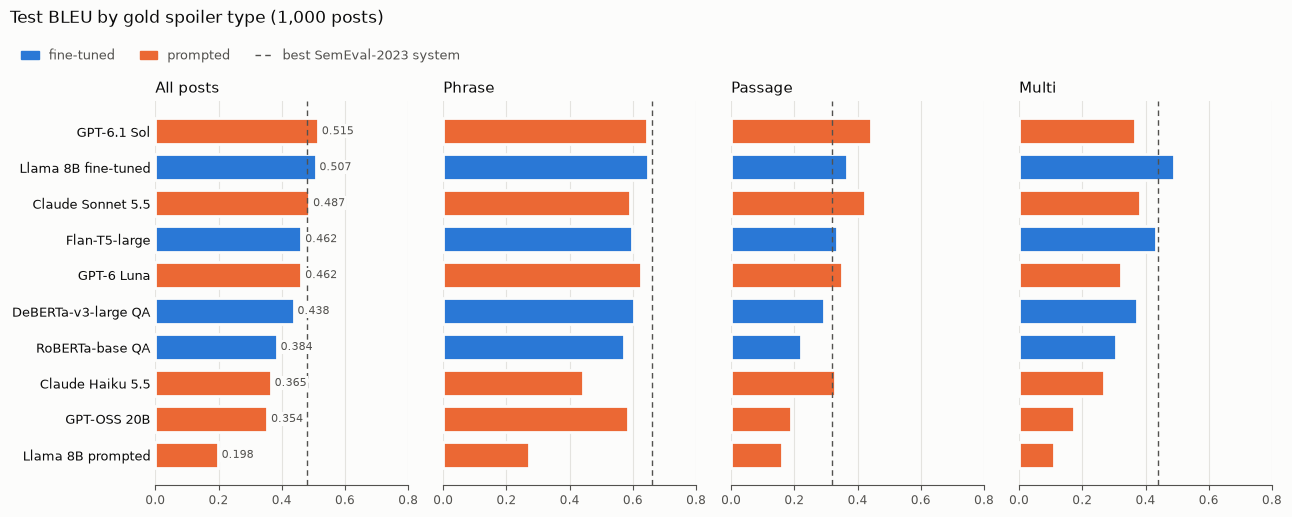

In [3]:
BEST_SEMEVAL = {"all": 0.48, "phrase": 0.66, "passage": 0.32, "multi": 0.44}
charted = sorted([s for s in SYSTEMS if s["family"] != "baseline"], key=lambda s: scores[s["key"]]["spoiler"]["all"]["bleu"])
y = np.arange(len(charted))
fig, axes = plt.subplots(1, 4, figsize=(13, 4.8), sharey=True, facecolor=SURFACE)
for ax, group, title in zip(axes, ["all"] + TYPES, ["All posts", "Phrase", "Passage", "Multi"]):
    values = [scores[s["key"]]["spoiler"][group]["bleu"] for s in charted]
    style_axis(ax)
    ax.barh(y, values, height=0.72, color=[FAMILY_COLORS[s["family"]] for s in charted], edgecolor=SURFACE,
            linewidth=2, zorder=2)
    ax.axvline(BEST_SEMEVAL[group], color=INK_2, linestyle=(0, (4, 3)), linewidth=1, zorder=3)
    if group == "all":  # values only in the first panel, to keep the chart readable
        for yi, v in zip(y, values):
            ax.text(v + 0.012, yi, f"{v:.3f}", va="center", fontsize=8, color=INK_2, zorder=4,
                    bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1.0})
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlim(0, 0.8)
    ax.tick_params(axis="y", length=0, colors=INK, labelsize=9)
axes[0].set_yticks(y, [s["short"] for s in charted])
handles = [Patch(color=FAMILY_COLORS["fine-tuned"], label="fine-tuned"), Patch(color=FAMILY_COLORS["prompted"], label="prompted"),
           Line2D([0], [0], color=INK_2, linestyle=(0, (4, 3)), linewidth=1, label="best SemEval-2023 system")]
fig.text(0.01, 1.04, "Test BLEU by gold spoiler type (1,000 posts)", color=INK, fontsize=12, ha="left")
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.01, 1.01), ncol=3, frameon=False, fontsize=9,
           labelcolor=INK_2, handlelength=1.4)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIG_DIR / "compare-bleu-by-type.png", dpi=200, facecolor=SURFACE, bbox_inches="tight")
plt.show()

## 3. Is the difference real? Paired bootstrap

With 1,000 test posts (and only 174 multi posts), a difference of a point or two of BLEU can be luck. For each pair of systems we compare their per-post BLEU on the **same** posts:
1. Resample the posts with replacement 10,000 times.
2. Each time, recompute the mean BLEU difference.

The tables give the observed difference (positive: the prompted LLM is better), its 95% interval, and two *p*-values: **p (not better)** is the share of resamples in which the prompted LLM is not better (one-sided), and **p (two-sided)** tests for a difference in either direction. A *p* of 0 means fewer than 1 in 10,000.

Each table runs 24 tests (6 models × 4 subsets), so a few small *p*-values could appear by chance. The column **significant (Holm)** applies the Holm–Bonferroni correction to the two-sided *p*-values at the 5% level within each table; the sign of the difference says which side wins.

**3a. Prompted LLMs vs our strong baseline:** each prompted LLM against the Milestone 2 RoBERTa-base QA system.

In [4]:
def bootstrap_table(against, p_column="p (two-sided)"):
    rows = []
    for s in SYSTEMS:
        if s["family"] == "prompted":
            rows += C.bootstrap_rows(test, bleu[s["key"]], bleu[against], s["label"], BY_KEY[against]["label"])
    table = pd.DataFrame(rows)
    table["significant (Holm)"] = C.holm(table[p_column])
    return table


vs_baseline = bootstrap_table("roberta-base-qa")
save_table(vs_baseline, "compare-bootstrap-vs-baseline")
vs_baseline.style.format(precision=4)

,system,compared with,posts,n,difference,95% low,95% high,p (not better),p (two-sided),significant (Holm)
0,"Llama 3.1 8B, prompted",RoBERTa-base QA (M2 strong baseline),all,1000,-0.1865,-0.2152,-0.1581,1.0000,0.0000,True
1,"Llama 3.1 8B, prompted",RoBERTa-base QA (M2 strong baseline),phrase,423,-0.3003,-0.3472,-0.2535,1.0000,0.0000,True
2,"Llama 3.1 8B, prompted",RoBERTa-base QA (M2 strong baseline),passage,403,-0.0622,-0.1050,-0.0209,0.9978,0.0044,True
3,"Llama 3.1 8B, prompted",RoBERTa-base QA (M2 strong baseline),multi,174,-0.1977,-0.2572,-0.1373,1.0000,0.0000,True
4,GPT-OSS 20B,RoBERTa-base QA (M2 strong baseline),all,1000,-0.0302,-0.0567,-0.0039,0.9888,0.0224,False
5,GPT-OSS 20B,RoBERTa-base QA (M2 strong baseline),phrase,423,0.0147,-0.0275,0.0573,0.2427,0.4854,False
6,GPT-OSS 20B,RoBERTa-base QA (M2 strong baseline),passage,403,-0.0326,-0.0731,0.0079,0.9442,0.1116,False
7,GPT-OSS 20B,RoBERTa-base QA (M2 strong baseline),multi,174,-0.1337,-0.1934,-0.0739,1.0000,0.0000,True
8,Claude Sonnet 5.5,RoBERTa-base QA (M2 strong baseline),all,1000,0.1028,0.0749,0.1310,0.0000,0.0000,True
9,Claude Sonnet 5.5,RoBERTa-base QA (M2 strong baseline),phrase,423,0.0207,-0.0239,0.0668,0.1818,0.3636,False


**3b. Prompted LLMs vs fine-tuning:** each prompted LLM against our best fine-tuned model, Llama 3.1 8B with QLoRA (Milestone 3). A negative difference means the fine-tuned model is better.

In [5]:
vs_finetuned = bootstrap_table("llama-qlora")
save_table(vs_finetuned, "compare-bootstrap-vs-finetuned")
vs_finetuned.style.format(precision=4)

,system,compared with,posts,n,difference,95% low,95% high,p (not better),p (two-sided),significant (Holm)
0,"Llama 3.1 8B, prompted","Llama 3.1 8B, fine-tuned (QLoRA)",all,1000,-0.3093,-0.3374,-0.2808,1.0000,0.0000,True
1,"Llama 3.1 8B, prompted","Llama 3.1 8B, fine-tuned (QLoRA)",phrase,423,-0.3780,-0.4232,-0.3333,1.0000,0.0000,True
2,"Llama 3.1 8B, prompted","Llama 3.1 8B, fine-tuned (QLoRA)",passage,403,-0.2062,-0.2505,-0.1631,1.0000,0.0000,True
3,"Llama 3.1 8B, prompted","Llama 3.1 8B, fine-tuned (QLoRA)",multi,174,-0.3808,-0.4456,-0.3156,1.0000,0.0000,True
4,GPT-OSS 20B,"Llama 3.1 8B, fine-tuned (QLoRA)",all,1000,-0.1529,-0.1806,-0.1253,1.0000,0.0000,True
5,GPT-OSS 20B,"Llama 3.1 8B, fine-tuned (QLoRA)",phrase,423,-0.0630,-0.1037,-0.0234,0.9996,0.0008,True
6,GPT-OSS 20B,"Llama 3.1 8B, fine-tuned (QLoRA)",passage,403,-0.1766,-0.2220,-0.1311,1.0000,0.0000,True
7,GPT-OSS 20B,"Llama 3.1 8B, fine-tuned (QLoRA)",multi,174,-0.3169,-0.3811,-0.2533,1.0000,0.0000,True
8,Claude Sonnet 5.5,"Llama 3.1 8B, fine-tuned (QLoRA)",all,1000,-0.0200,-0.0461,0.0073,0.9237,0.1526,False
9,Claude Sonnet 5.5,"Llama 3.1 8B, fine-tuned (QLoRA)",phrase,423,-0.0570,-0.0966,-0.0196,0.9979,0.0042,True


## 4. Same model, prompted vs fine-tuned: Llama 3.1 8B

Llama 3.1 8B Instruct is the only model we ran both ways: prompted through Ollama (4-bit, with the number of worked examples chosen on dev) and fine-tuned with QLoRA (4-bit NF4 base, LoRA adapters, Milestone 3). Both read the post and the article. The table shows how they answer, not just how well:
- **predicted type shares** against the gold shares (42% phrase, 40% passage, 18% multi);
- **items per post:** how many separate spoilers they give;
- **several items, phrase/passage:** answers typed phrase or passage that still contain more than one spoiler (the prompt asks for exactly one). A prediction file joins them into one string, so this comes from the prompted model's raw replies; the fine-tuned model's raw generations weren't saved;
- **words per post:** median length of the whole answer as scored, for gold phrase and gold passage posts;
- **copied from the article:** the share of spoiler items that appear word for word in the article (for the prompted model: its raw items, before snapping);
- **zero BLEU:** posts whose answer shares no word with the gold spoiler.

Below it, the two type confusion matrices (rows: gold type, columns: predicted type).

In [6]:
def behaviour(key, raw_path=None):
    p = preds[key]
    uuids = [u for u in gold if u in p]
    types = pd.Series([p[u]["spoilerType"] for u in uuids])
    if raw_path:  # the prompted model: its own items, from the raw replies
        raw = {row["uuid"]: llm.parse_response(row["text"]) for row in load_jsonl(raw_path)}
        item_lists = {u: raw[u][1] for u in uuids}
        several = float(np.mean([len(raw[u][1]) > 1 for u in uuids if raw[u][0] in ("phrase", "passage")]))
    else:
        item_lists = {u: C.items(p[u]["spoiler"]) for u in uuids}
        several = None
    copied = [C.squash(x) in C.squash(build_context(gold[u])) for u in uuids for x in item_lists[u] if C.squash(x)]
    row = {f"predicted {t}": float((types == t).mean()) for t in TYPES}
    row["items per post"] = float(np.mean([len(v) for v in item_lists.values()]))
    row["several items, phrase/passage"] = several
    for t in ("phrase", "passage"):
        row[f"words per post (gold {t})"] = float(np.median([C.word_count(as_text(p[u]["spoiler"])) for u in uuids
                                                            if spoiler_type(gold[u]) == t]))
    row["copied from the article"] = float(np.mean(copied))
    row["zero BLEU"] = float((bleu[key][uuids] == 0).mean())
    return row


prompted_llama = BY_KEY["llama3.1-8b"]
raw_file = OUTPUT_DIR / "raw" / f"{prompted_llama['run']}.jsonl"
gold_row = {f"predicted {t}": float(np.mean([spoiler_type(r) == t for r in test])) for t in TYPES}
gold_row.update({"items per post": float(np.mean([len(r["spoiler"]) for r in test])), "several items, phrase/passage": 0.0,
                 **{f"words per post (gold {t})": float(np.median([C.word_count(as_text(r["spoiler"])) for r in test
                                                                  if spoiler_type(r) == t])) for t in ("phrase", "passage")}})
llama_rows = []
for key, label, path in [("llama3.1-8b", f"prompted ({prompted_llama['k']} worked examples)", raw_file), ("llama-qlora", "fine-tuned (QLoRA)", None)]:
    sp = scores[key]["spoiler"]
    llama_rows.append({"Llama 3.1 8B": label, "BLEU": sp["all"]["bleu"], **{t: sp[t]["bleu"] for t in TYPES},
                       "type bal. acc.": scores[key]["type"]["balanced-accuracy"], **behaviour(key, path)})
llama_rows.append({"Llama 3.1 8B": "gold (for reference)", **gold_row})
llama_table = pd.DataFrame(llama_rows)
save_table(llama_table, "compare-llama-prompted-vs-finetuned", digits=3)
display(llama_table.style.format(precision=3, na_rep=""))

for key in ("llama3.1-8b", "llama-qlora"):
    confusion = pd.crosstab(pd.Series([spoiler_type(gold[u]) for u in preds[key]], name="gold"),
                            pd.Series([preds[key][u]["spoilerType"] for u in preds[key]], name="predicted"))
    print(BY_KEY[key]["label"])
    display(confusion.reindex(index=TYPES, columns=TYPES, fill_value=0))

,Llama 3.1 8B,BLEU,phrase,passage,multi,type bal. acc.,predicted phrase,predicted passage,predicted multi,items per post,"several items, phrase/passage",words per post (gold phrase),words per post (gold passage),copied from the article,zero BLEU
0,prompted (0 worked examples),0.198,0.270,0.160,0.110,0.545,0.138,0.707,0.155,2.519,0.058,9.000,17.000,0.974,0.310
1,fine-tuned (QLoRA),0.507,0.648,0.366,0.491,0.758,0.433,0.413,0.154,1.437,,2.000,20.000,0.991,0.111
2,gold (for reference),,,,,,0.423,0.403,0.174,1.463,0.000,2.000,18.000,,


Llama 3.1 8B, prompted


predicted,phrase,passage,multi
gold,,,
phrase,99,294,30
passage,25,347,31
multi,14,66,94


Llama 3.1 8B, fine-tuned (QLoRA)


predicted,phrase,passage,multi
gold,,,
phrase,337,71,15
passage,66,318,19
multi,30,24,120


## 5. Probes on 300 test posts: few-shot, zero-shot, closed-book

`1-prompted-llms.ipynb` asked every prompted model about the same stratified sample of 300 test posts in two more ways:
- **zero-shot:** the post and the article, but no worked examples;
- **closed-book:** the post only, no article (with the model's usual worked examples, also without articles), not snapped.

Here the main few-shot answers are scored on the same 300 posts, so the three setups compare like for like. For Llama and GPT-OSS the best *k* was 0, so their "few-shot" and "zero-shot" runs are the same setup asked twice (temperature 0, so nearly identical). The fine-tuned Llama is added for reference.

A model that scores well **closed-book** knows the answer without reading the article: it may have seen this public dataset or the news stories in its training data.

In [7]:
probe = llm.stratified_sample(test, 300, seed=0)  # the same sample as in 1-prompted-llms.ipynb
probe_ids = [r["uuid"] for r in probe]


def probe_bleu(pred_path):
    return C.per_post_bleu(probe, C.load_preds(pred_path)) if pred_path.exists() else None


def subset_scores(series):
    out = {"BLEU": float(series.mean())}
    for t in TYPES:
        out[t] = float(series[[u for u in series.index if spoiler_type(gold[u]) == t]].mean())
    return out


probe_runs = {}
probe_rows = []
for s in SYSTEMS:
    if s["family"] != "prompted":
        continue
    k = s["k"]
    runs = {"few-shot": bleu[s["key"]][probe_ids],
            "zero-shot": probe_bleu(OUTPUT_DIR / "predictions" / f"{llm.run_name(s['key'], 'article', 0, 'test300')}.jsonl"),
            "closed-book": probe_bleu(OUTPUT_DIR / "predictions" / f"{llm.run_name(s['key'], 'closedbook', k, 'test300')}.jsonl")}
    probe_runs[s["key"]] = runs
    for setup, series in runs.items():
        if series is not None:
            probe_rows.append({"system": s["label"], "setup": setup, "worked examples": 0 if setup == "zero-shot" else k,
                               "posts": len(series), **subset_scores(series)})
probe_rows.append({"system": BY_KEY["llama-qlora"]["label"], "setup": "fine-tuned", "worked examples": "",
                   "posts": len(probe_ids), **subset_scores(bleu["llama-qlora"][probe_ids])})
probe_table = pd.DataFrame(probe_rows)
save_table(probe_table, "compare-probes")
probe_table.style.format(precision=4, na_rep="")

,system,setup,worked examples,posts,BLEU,phrase,passage,multi
0,"Llama 3.1 8B, prompted",few-shot,0,300,0.1842,0.2639,0.1386,0.0956
1,"Llama 3.1 8B, prompted",zero-shot,0,300,0.1842,0.2639,0.1386,0.0956
2,"Llama 3.1 8B, prompted",closed-book,0,300,0.0198,0.0467,0.0000,0.0000
3,GPT-OSS 20B,few-shot,0,300,0.3580,0.5679,0.2145,0.1795
4,GPT-OSS 20B,zero-shot,0,300,0.3415,0.5530,0.1965,0.1621
5,GPT-OSS 20B,closed-book,0,300,0.0295,0.0676,0.0011,0.0026
6,Claude Sonnet 5.5,few-shot,6,300,0.4992,0.6161,0.4208,0.3964
7,Claude Sonnet 5.5,zero-shot,0,300,0.4673,0.5746,0.4008,0.3602
8,Claude Sonnet 5.5,closed-book,6,300,0.0663,0.1545,0.0000,0.0051
9,Claude Haiku 5.5,few-shot,3,300,0.3859,0.4685,0.3556,0.2544


The same numbers as a chart (overall BLEU on the 300 posts), saved as `output/figures/compare-probes.png`. Then a bootstrap of few-shot against zero-shot for the models whose best *k* was above 0: do the worked examples help significantly?

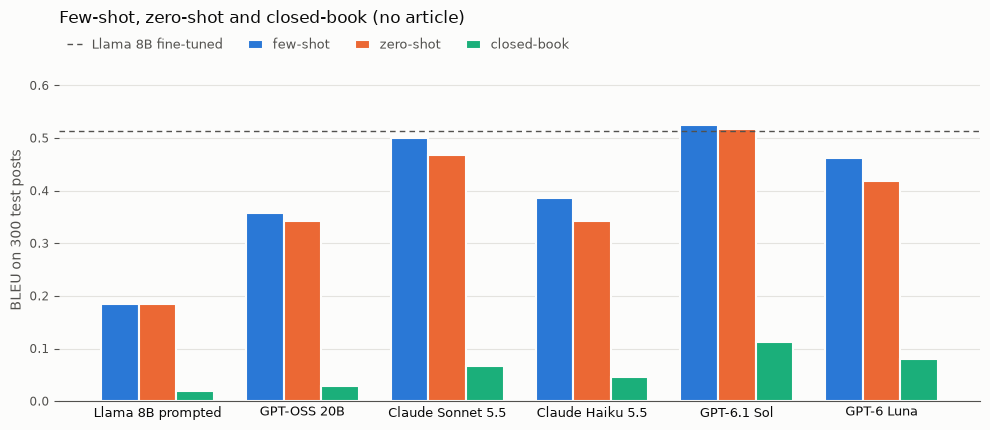

,system,compared with,posts,n,difference,95% low,95% high,p (not better),p (two-sided)
0,"Claude Sonnet 5.5, 6 worked examples",zero-shot,all,300,0.0319,0.0030,0.0614,0.0156,0.0312
1,"Claude Sonnet 5.5, 6 worked examples",zero-shot,phrase,127,0.0415,-0.0001,0.0861,0.0255,0.0510
2,"Claude Sonnet 5.5, 6 worked examples",zero-shot,passage,121,0.0200,-0.0217,0.0647,0.1750,0.3500
3,"Claude Sonnet 5.5, 6 worked examples",zero-shot,multi,52,0.0362,-0.0471,0.1222,0.2037,0.4074
4,"Claude Haiku 5.5, 3 worked examples",zero-shot,all,300,0.0427,-0.0029,0.0898,0.0343,0.0686
5,"Claude Haiku 5.5, 3 worked examples",zero-shot,phrase,127,0.0196,-0.0555,0.0943,0.3044,0.6088
6,"Claude Haiku 5.5, 3 worked examples",zero-shot,passage,121,0.0681,-0.0070,0.1450,0.0391,0.0782
7,"Claude Haiku 5.5, 3 worked examples",zero-shot,multi,52,0.0399,-0.0421,0.1247,0.1750,0.3500
8,"GPT-6.1 Sol, 6 worked examples",zero-shot,all,300,0.0086,-0.0113,0.0291,0.1980,0.3960
9,"GPT-6.1 Sol, 6 worked examples",zero-shot,phrase,127,-0.0012,-0.0221,0.0175,0.5428,0.9144


In [8]:
setups = ["few-shot", "zero-shot", "closed-book"]
prompted = [s for s in SYSTEMS if s["family"] == "prompted"]
x = np.arange(len(prompted))
width = 0.26
fig, ax = plt.subplots(figsize=(10, 4.4), facecolor=SURFACE)
style_axis(ax, grid_axis="y")
for j, setup in enumerate(setups):
    values = [probe_runs[s["key"]][setup].mean() for s in prompted]
    ax.bar(x + (j - 1) * width, values, width, color=SERIES[j], edgecolor=SURFACE, linewidth=1.5, label=setup, zorder=2)
ax.axhline(bleu["llama-qlora"][probe_ids].mean(), color=INK_2, linestyle=(0, (4, 3)), linewidth=1, zorder=3,
           label="Llama 8B fine-tuned")
ax.set_xticks(x, [s["short"] for s in prompted], color=INK, fontsize=9)
ax.tick_params(axis="x", length=0)
ax.set_ylabel("BLEU on 300 test posts", color=INK_2)
ax.set_ylim(0, 0.65)
ax.set_title("Few-shot, zero-shot and closed-book (no article)", loc="left", color=INK, fontsize=12, pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, frameon=False, fontsize=9, labelcolor=INK_2,
          handlelength=1.2, borderaxespad=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "compare-probes.png", dpi=200, facecolor=SURFACE)
plt.show()

few_vs_zero = []
for s in prompted:
    if s["k"] > 0:
        few_vs_zero += C.bootstrap_rows(probe, probe_runs[s["key"]]["few-shot"], probe_runs[s["key"]]["zero-shot"],
                                        f"{s['label']}, {s['k']} worked examples", "zero-shot")
few_vs_zero = pd.DataFrame(few_vs_zero)
save_table(few_vs_zero, "compare-bootstrap-fewshot-vs-zeroshot")
few_vs_zero.style.format(precision=4)

**What do the models get right without the article?** For each model, the share of the 300 posts where the closed-book answer scores BLEU ≥ 0.5, per gold type. Then the posts that at least three models get right closed-book, with every closed-book answer: are these posts guessable from the post alone, or does it look like memory?

In [9]:
closed = {}
for s in prompted:
    path = OUTPUT_DIR / "predictions" / f"{llm.run_name(s['key'], 'closedbook', s['k'], 'test300')}.jsonl"
    closed[s["key"]] = C.load_preds(path)
hit_rows = []
for s in prompted:
    series = probe_runs[s["key"]]["closed-book"]
    hit_rows.append({"system": s["label"], "BLEU >= 0.5 (all)": float((series >= 0.5).mean()),
                     **{f"BLEU >= 0.5 ({t})": float((series[[u for u in series.index if spoiler_type(gold[u]) == t]] >= 0.5).mean())
                        for t in TYPES}})
hits = pd.DataFrame(hit_rows)
save_table(hits, "compare-closedbook-hits", digits=3)
display(hits.style.format(precision=3))

n_right = sum((probe_runs[s["key"]]["closed-book"] >= 0.5).astype(int) for s in prompted)
shared = n_right[n_right >= 3].sort_values(ascending=False).index
print(f"{len(shared)} of 300 posts are answered closed-book (BLEU >= 0.5) by at least 3 of the {len(prompted)} models")
pd.DataFrame([{"post": post_text(gold[u]), "gold": as_text(gold[u]["spoiler"]), "models right": int(n_right[u]),
               **{s["short"]: as_text(closed[s["key"]][u]["spoiler"]) for s in prompted}} for u in shared[:12]])

,system,BLEU >= 0.5 (all),BLEU >= 0.5 (phrase),BLEU >= 0.5 (passage),BLEU >= 0.5 (multi)
0,"Llama 3.1 8B, prompted",0.020,0.047,0.000,0.000
1,GPT-OSS 20B,0.033,0.079,0.000,0.000
2,Claude Sonnet 5.5,0.063,0.150,0.000,0.000
3,Claude Haiku 5.5,0.043,0.102,0.000,0.000
4,GPT-6.1 Sol,0.107,0.244,0.000,0.019
5,GPT-6 Luna,0.083,0.189,0.000,0.019


16 of 300 posts are answered closed-book (BLEU >= 0.5) by at least 3 of the 6 models


,post,gold,models right,Llama 8B prompted,GPT-OSS 20B,Claude Sonnet 5.5,Claude Haiku 5.5,GPT-6.1 Sol,GPT-6 Luna
0,Jennifer Lawrence Has a Big ‘F*ck You’ For a Candidate But You Have to Guess Which One,Trump,6,Donald Trump,Donald Trump,Donald Trump,Donald Trump,Donald Trump,Donald Trump
1,This One Ingredient Could Make Peanut Butter Deadly For Your Dog,Xylitol,5,"Xylitol, a sugar substitute commonly found in peanut butter products, is toxic to dogs.",xylitol,Xylitol,Xylitol,Xylitol,Xylitol
2,The disease that kills one woman a minute in the U.S.,heart disease,5,Breast cancer,Heart disease,Heart disease,Heart disease,Heart disease,Heart disease
3,DNA testing has for the first time confirmed the identity of the bacteria behind Londo...,Yersinia pestis bacterium,5,The bacteria is Yersinia pestis.,Yersinia pestis,Yersinia pestis,Yersinia pestis,Yersinia pestis,Yersinia pestis
4,The healthiest state in America is...,Hawaii,5,Hawaii,Maine,Hawaii,Hawaii,Hawaii,Hawaii
5,This is the most booming big city in America:,"Austin, Texas",4,Austin,New York City,"Austin, Texas","Austin, Texas","Austin, Texas","Austin, Texas"
6,What's the world's most dangerous drug?,alcohol,4,Fentanyl,Methamphetamine,Alcohol,Alcohol,Alcohol,Alcohol
7,There’s an airline people dislike even more than United,Spirit Airlines,4,Spirit,American Airlines,Spirit Airlines,Spirit Airlines,Spirit Airlines,Spirit Airlines
8,Pope Francis racks up another surprising magazine cover,Rolling Stone,4,Pope Francis appears on the cover of Playboy magazine,The Economist,Rolling Stone,Rolling Stone,Rolling Stone,Rolling Stone
9,This is the secret code word for when Queen Elizabeth dies,London Bridge is down,3,Operation London Bridge,RIP,London Bridge is down,"""London Bridge is down""",London Bridge is down.,“London Bridge is down”


## 6. Does snapping help?

The prompted models are asked to copy the spoiler word for word, but they sometimes change punctuation or a word. Snapping replaces each predicted spoiler by the closest span of the article (`spoilerqa/llm.py: snap_span`). The table gives test BLEU with and without snapping, and how the spoilers were snapped (from `output/llm-test-runs.csv`): **exact** (already in the article), **fuzzy** (a close span was found and used instead) or **kept** (nothing close; left as written).

In [10]:
runs_table = pd.read_csv(OUTPUT_DIR / "llm-test-runs.csv")
main_runs = runs_table[runs_table["setup"] == "few-shot"].set_index("model")
snap_rows = []
for s in prompted:
    r = main_runs.loc[s["key"]]
    snap_rows.append({"system": s["label"], "BLEU snapped": r["BLEU"], "BLEU unsnapped": r["BLEU unsnapped"],
                      "gain": r["BLEU"] - r["BLEU unsnapped"], "exact / fuzzy / kept": r["exact / fuzzy / kept"]})
snap_table = pd.DataFrame(snap_rows)
save_table(snap_table, "compare-snapping")
snap_table.style.format(precision=4)

,system,BLEU snapped,BLEU unsnapped,gain,exact / fuzzy / kept
0,"Llama 3.1 8B, prompted",0.1978,0.1938,0.0040,93% / 6% / 1%
1,GPT-OSS 20B,0.3541,0.3457,0.0084,86% / 9% / 6%
2,Claude Sonnet 5.5,0.4871,0.4833,0.0038,98% / 2% / 0%
3,Claude Haiku 5.5,0.3655,0.3593,0.0062,95% / 4% / 0%
4,GPT-6.1 Sol,0.5147,0.5143,0.0004,100% / 0% / 0%
5,GPT-6 Luna,0.4620,0.4645,-0.0025,96% / 1% / 3%


## 7. Cost and time

**Prompted LLMs** (main test run, 1,000 posts), from the token counts the APIs returned:
- **input / output tokens per post:** input includes the worked examples (cached reads and writes included); output includes the models' reasoning tokens (shown apart for OpenAI, which reports them).
- **US$ per 1,000 posts** at standard prices and at batch prices (half), computed from the tokens whichever way the run was actually made.
- **spent (whole extension):** what all runs of this model cost us (dev sweep, test run, probes), each answer at the price we actually paid (batch or direct).
- **seconds per post:** median time per request, where it was measured: the local models answer one post at a time; GPT-6.1 Sol's test run was direct, 8 requests in parallel. Batch answers have no per-request time.

**Fine-tuned models:** training time on one NVIDIA L4 GPU, for the learning rate we kept and for the whole 3-learning-rate sweep (from the sweep files in `output/finetuned/training/`). Running them on the test set takes minutes on the same GPU; they cost nothing per post beyond the GPU time.

In [11]:
RAW_DIR = OUTPUT_DIR / "raw"
cost_rows = []
for s in prompted:
    rows = load_jsonl(RAW_DIR / f"{s['run']}.jsonl")
    usage = pd.DataFrame([r.get("usage") or {} for r in rows]).fillna(0)
    model_id = llm.MODELS[s["key"]]["model"]
    local = llm.MODELS[s["key"]]["backend"] == "ollama"
    input_tokens = usage.get("input_tokens", 0) + usage.get("cache_read_input_tokens", 0) + usage.get("cache_creation_input_tokens", 0)
    seconds = [r["seconds"] for r in rows if r.get("seconds")]
    spent = sum(llm.run_cost(load_jsonl(p), model_id) or 0 for p in RAW_DIR.glob(f"{s['key']}_*.jsonl"))
    cost_rows.append({
        "system": s["label"], "runs on": "this Mac (Ollama)" if local else "API",
        "input tokens per post": float(input_tokens.mean()), "output tokens per post": float(usage["output_tokens"].mean()),
        "of which reasoning": float(usage["reasoning_tokens"].mean()) if "reasoning_tokens" in usage else None,
        "US$ per 1,000 posts (standard)": None if local else llm.run_cost(rows, model_id, batch=False) * 1000 / len(rows),
        "US$ per 1,000 posts (batch)": None if local else llm.run_cost(rows, model_id, batch=True) * 1000 / len(rows),
        "spent, whole extension (US$)": None if local else spent,
        "seconds per post (median)": float(np.median(seconds)) if seconds else None,
    })
cost_table = pd.DataFrame(cost_rows)
save_table(cost_table, "compare-cost-prompted", digits=2)
display(cost_table.style.format(precision=2, na_rep=""))

train_rows = []
for s in SYSTEMS:
    if s["family"] != "fine-tuned":
        continue
    stem = s["stem"]
    sweep_path = OUTPUT_DIR / "finetuned" / "training" / f"{stem}-sweep.json"
    settings_path = OUTPUT_DIR / "finetuned" / "training" / f"{stem}-settings.json"
    if not sweep_path.exists():
        continue
    sweep = json.loads(sweep_path.read_text())
    chosen = json.loads(settings_path.read_text())["learning_rate"] if settings_path.exists() else None
    # the Milestone 2 sweep didn't record times: each RoBERTa-base learning rate took about 8.6 minutes on the L4
    minutes = [r.get("train_minutes", 8.6) for r in sweep]
    kept = next((m for r, m in zip(sweep, minutes) if chosen is not None and abs(r["learning_rate"] - chosen) < 1e-12), None)
    train_rows.append({"system": s["label"], "learning rate kept": f"{chosen:g}" if chosen else "",
                       "GPU hours, kept run": kept / 60 if kept else None, "GPU hours, whole sweep": sum(minutes) / 60,
                       "test BLEU": scores[s["key"]]["spoiler"]["all"]["bleu"]})
train_table = pd.DataFrame(train_rows)
save_table(train_table, "compare-cost-finetuned", digits=2)
train_table.style.format(precision=2, na_rep="")

,system,runs on,input tokens per post,output tokens per post,of which reasoning,"US$ per 1,000 posts (standard)","US$ per 1,000 posts (batch)","spent, whole extension (US$)",seconds per post (median)
0,"Llama 3.1 8B, prompted",this Mac (Ollama),877.72,111.31,,,,,2.50
1,GPT-OSS 20B,this Mac (Ollama),929.19,72.33,,,,,2.22
2,Claude Sonnet 5.5,API,4021.10,58.82,,3.28,1.64,3.46,
3,Claude Haiku 5.5,API,2896.10,102.36,,0.17,0.09,0.18,
4,GPT-6.1 Sol,API,2381.19,44.95,2.77,5.21,2.61,6.99,1.95
5,GPT-6 Luna,API,1684.19,53.84,15.17,0.20,0.10,0.20,


,system,learning rate kept,"GPU hours, kept run","GPU hours, whole sweep",test BLEU
0,RoBERTa-base QA (M2 strong baseline),1e-05,0.14,0.43,0.38
1,DeBERTa-v3-large QA,1e-05,1.10,3.30,0.44
2,Flan-T5-large,0.0003,2.79,8.40,0.46
3,"Llama 3.1 8B, fine-tuned (QLoRA)",0.0002,4.04,12.06,0.51
